# Machine Learning Capstone Project

## Water Treatment Plant Clustering

### Review 2 - Clustering Track

**Problem Statement:**  
Wastewater treatment plants collect measurements at different stages of the treatment process. Identifying patterns in these measurements can help reveal groups of similar operating conditions.

**Objective:**  
Apply unsupervised machine learning algorithms to the Water Treatment Plant dataset to identify clusters of similar observations, evaluate clustering performance, and visualise the resulting clusters.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# 1. Dataset Loading

The Water Treatment Plant dataset contains measurements from different stages of a wastewater treatment process. The raw data file does not include column headers, so the attribute names are assigned explicitly when loading the data.

In [2]:
columns = [
    "Date",
    "Q-E", "ZN-E", "PH-E", "DBO-E", "DQO-E",
    "SS-E", "SSV-E", "SED-E", "COND-E",
    "PH-P", "DBO-P", "SS-P", "SSV-P", "SED-P", "COND-P",
    "PH-D", "DBO-D", "DQO-D", "SS-D", "SSV-D", "SED-D", "COND-D",
    "PH-S", "DBO-S", "DQO-S", "SS-S", "SSV-S", "SED-S", "COND-S",
    "RD-DBO-P", "RD-SS-P", "RD-SED-P",
    "RD-DBO-S", "RD-DQO-S",
    "RD-DBO-G", "RD-DQO-G", "RD-SS-G", "RD-SED-G"
]

df = pd.read_csv(
    "water-treatment.data",
    header=None,
    names=columns,
    na_values="?",
    skipinitialspace=True
)

df.head()

,Date,Q-E,ZN-E,PH-E,DBO-E,DQO-E,SS-E,SSV-E,SED-E,COND-E,...,COND-S,RD-DBO-P,RD-SS-P,RD-SED-P,RD-DBO-S,RD-DQO-S,RD-DBO-G,RD-DQO-G,RD-SS-G,RD-SED-G
0,D-1/3/90,44101.0,1.5,7.8,NaN,407.0,166.0,66.3,4.5,2110,...,2000.0,NaN,58.8,95.5,NaN,70.0,NaN,79.4,87.3,99.6
1,D-2/3/90,39024.0,3.0,7.7,NaN,443.0,214.0,69.2,6.5,2660,...,2590.0,NaN,60.7,94.8,NaN,80.8,NaN,79.5,92.1,100.0
2,D-4/3/90,32229.0,5.0,7.6,NaN,528.0,186.0,69.9,3.4,1666,...,1888.0,NaN,58.2,95.6,NaN,52.9,NaN,75.8,88.7,98.5
3,D-5/3/90,35023.0,3.5,7.9,205.0,588.0,192.0,65.6,4.5,2430,...,1840.0,33.1,64.2,95.3,87.3,72.3,90.2,82.3,89.6,100.0
4,D-6/3/90,36924.0,1.5,8.0,242.0,496.0,176.0,64.8,4.0,2110,...,2120.0,NaN,62.7,95.6,NaN,71.0,92.1,78.2,87.5,99.5


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (527, 39)

Column Names:
['Date', 'Q-E', 'ZN-E', 'PH-E', 'DBO-E', 'DQO-E', 'SS-E', 'SSV-E', 'SED-E', 'COND-E', 'PH-P', 'DBO-P', 'SS-P', 'SSV-P', 'SED-P', 'COND-P', 'PH-D', 'DBO-D', 'DQO-D', 'SS-D', 'SSV-D', 'SED-D', 'COND-D', 'PH-S', 'DBO-S', 'DQO-S', 'SS-S', 'SSV-S', 'SED-S', 'COND-S', 'RD-DBO-P', 'RD-SS-P', 'RD-SED-P', 'RD-DBO-S', 'RD-DQO-S', 'RD-DBO-G', 'RD-DQO-G', 'RD-SS-G', 'RD-SED-G']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 527 entries, 0 to 526
Data columns (total 39 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Date      527 non-null    str    
 1   Q-E       509 non-null    float64
 2   ZN-E      524 non-null    float64
 3   PH-E      527 non-null    float64
 4   DBO-E     504 non-null    float64
 5   DQO-E     521 non-null    float64
 6   SS-E      526 non-null    float64
 7   SSV-E     516 non-null    float64
 8   SED-E     502 non-null    float64
 9   COND-E    527 non-null    int64  
 10  PH

# 2. Missing Values and Duplicate Records

Missing values and duplicate records are checked to assess the quality of the dataset. These checks help determine whether data cleaning is required before clustering.

In [4]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_values[missing_values["Missing Count"] > 0]

,Missing Count,Missing Percentage
Q-E,18,3.42
ZN-E,3,0.57
DBO-E,23,4.36
DQO-E,6,1.14
SS-E,1,0.19
SSV-E,11,2.09
SED-E,25,4.74
DBO-P,40,7.59
SSV-P,11,2.09
SED-P,24,4.55


In [5]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


# 3. Descriptive Statistics

Descriptive statistics are calculated to understand the distribution and variability of the dataset attributes. Measures such as mean, standard deviation, minimum, and maximum help identify differences in measurement scales and possible unusual values.

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Q-E,509.0,37226.567780,6635.999806,10050.0,32888.000,35990.00,41372.000,60081.0
ZN-E,524.0,2.359065,2.749509,0.1,0.900,1.50,3.000,33.5
PH-E,527.0,7.810057,0.246175,6.9,7.600,7.80,8.000,8.7
DBO-E,504.0,188.714286,62.062831,31.0,146.750,182.50,223.000,438.0
DQO-E,521.0,406.898273,120.362974,81.0,325.000,400.00,478.000,941.0
SS-E,526.0,227.444867,135.940589,98.0,170.000,196.00,242.000,2008.0
SSV-E,516.0,61.393217,12.415264,13.2,55.700,64.30,69.725,85.0
SED-E,502.0,4.593825,2.743947,0.4,3.100,4.50,5.500,36.0
COND-E,527.0,1478.620493,394.898019,651.0,1201.000,1406.00,1672.000,3230.0
PH-P,527.0,7.829981,0.226925,7.3,7.700,7.80,8.000,8.5


# 4. Data Cleaning and Feature Engineering

Remove unnecessary variables and prepare the numerical features for clustering.

In [7]:
# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Remove the date column and keep numerical features
X = df.drop(columns=["Date"]).copy()

# Convert values to numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Remove columns containing only missing values
X = X.dropna(axis=1, how="all")

print("Feature shape before imputation:", X.shape)
print("Missing values before imputation:", X.isnull().sum().sum())

Feature shape before imputation: (527, 38)
Missing values before imputation: 591


## Handle Missing Values

Replace missing numerical values with the median of each feature.

In [8]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

print("Missing values after imputation:", X.isnull().sum().sum())

Missing values after imputation: 0


## Feature Engineering

Remove constant features that do not contribute information to clustering.

In [9]:
constant_features = X.columns[X.nunique() <= 1].tolist()

X = X.drop(columns=constant_features)

print("Constant features removed:", constant_features)
print("Final feature shape:", X.shape)

X.head()

Constant features removed: []
Final feature shape: (527, 38)


,Q-E,ZN-E,PH-E,DBO-E,DQO-E,SS-E,SSV-E,SED-E,COND-E,PH-P,...,COND-S,RD-DBO-P,RD-SS-P,RD-SED-P,RD-DBO-S,RD-DQO-S,RD-DBO-G,RD-DQO-G,RD-SS-G,RD-SED-G
0,44101.0,1.5,7.8,182.5,407.0,166.0,66.3,4.5,2110.0,7.9,...,2000.0,39.6,58.8,95.5,85.4,70.0,90.2,79.4,87.3,99.6
1,39024.0,3.0,7.7,182.5,443.0,214.0,69.2,6.5,2660.0,7.7,...,2590.0,39.6,60.7,94.8,85.4,80.8,90.2,79.5,92.1,100.0
2,32229.0,5.0,7.6,182.5,528.0,186.0,69.9,3.4,1666.0,7.7,...,1888.0,39.6,58.2,95.6,85.4,52.9,90.2,75.8,88.7,98.5
3,35023.0,3.5,7.9,205.0,588.0,192.0,65.6,4.5,2430.0,7.8,...,1840.0,33.1,64.2,95.3,87.3,72.3,90.2,82.3,89.6,100.0
4,36924.0,1.5,8.0,242.0,496.0,176.0,64.8,4.0,2110.0,7.9,...,2120.0,39.6,62.7,95.6,85.4,71.0,92.1,78.2,87.5,99.5


# 5. Exploratory Data Analysis (EDA)

Visualise the distributions and correlations of the numerical features.

## Feature Distributions

Visualize the distribution of each numerical feature.

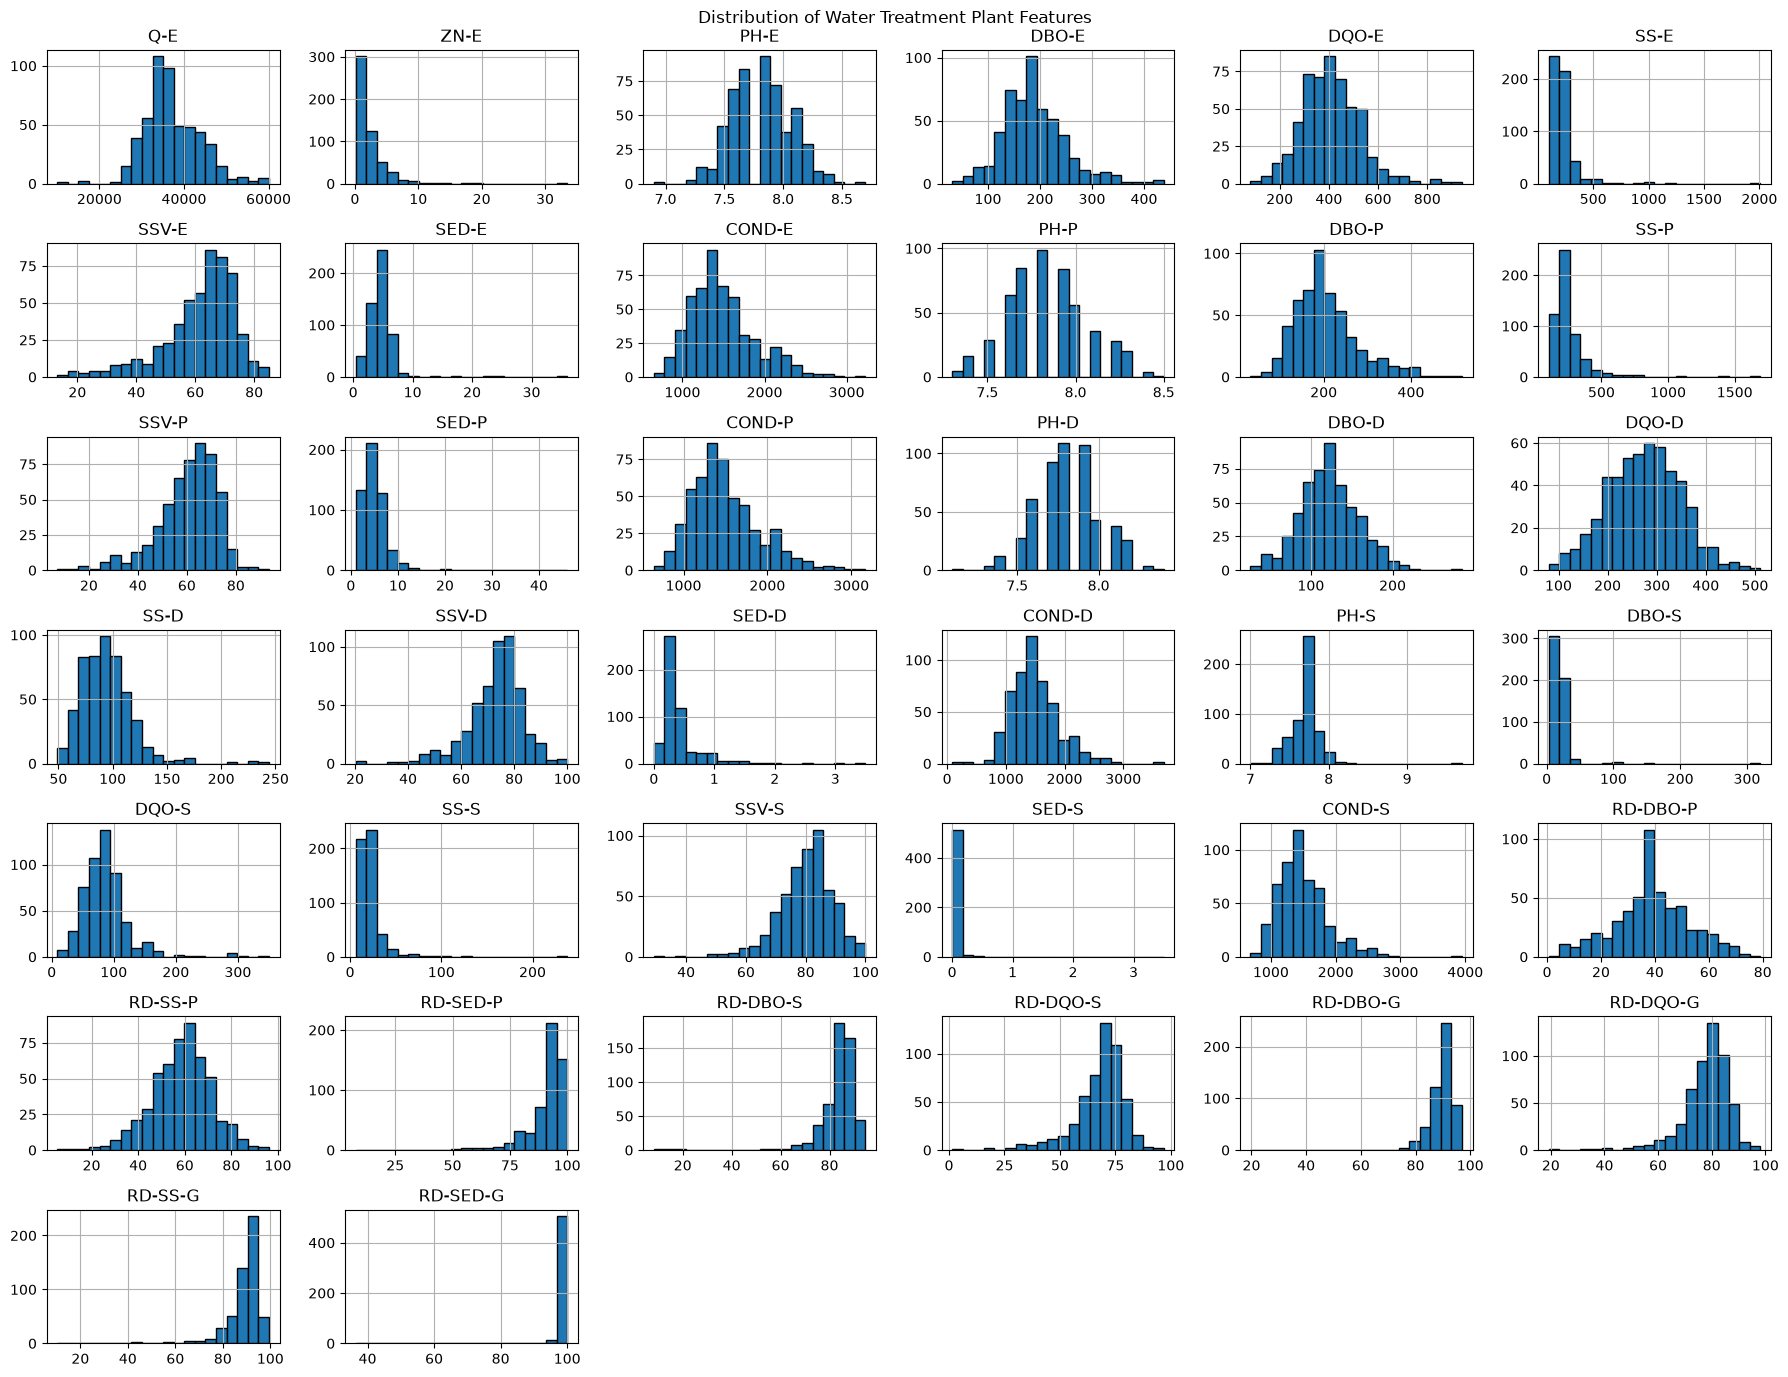

In [10]:
X.hist(figsize=(18, 14), bins=20, edgecolor="black")

plt.suptitle("Distribution of Water Treatment Plant Features")
plt.tight_layout()
plt.show()

### Observation

The plots show the distributions and ranges of the water-treatment measurements.

## Correlation Heatmap

Examine the correlations between numerical features.

In [ ]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    X.corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### Observation

The heatmap shows the strength and direction of relationships between the numerical features.

## Feature Scatter Plots

Examine the relationships between selected water-treatment measurements.

### pH vs Conductivity at the Entry Stage

This scatter plot examines the relationship between pH and conductivity in the incoming wastewater.

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=X,
    x="PH-E",
    y="COND-E",
    alpha=0.6
)

plt.title("pH vs Conductivity at the Entry Stage")
plt.xlabel("pH at Entry (PH-E)")
plt.ylabel("Conductivity at Entry (COND-E)")
plt.tight_layout()
plt.show()

### Incoming vs Outgoing BOD

This scatter plot compares the biological oxygen demand (BOD) of incoming wastewater with the BOD measured at the final treatment stage.

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=X,
    x="DBO-E",
    y="DBO-S",
    alpha=0.6
)

plt.title("Incoming vs Outgoing BOD")
plt.xlabel("Incoming BOD (DBO-E)")
plt.ylabel("Outgoing BOD (DBO-S)")
plt.tight_layout()
plt.show()

### Observation

The scatter plots show how selected water-treatment measurements vary together across observations.

# 6. Outlier Detection and Treatment

Outliers are inspected using boxplots and the IQR rule. K-Means and
hierarchical clustering are distance-based, so extreme values can pull
cluster centres towards them. Observations are not deleted because the
dataset is small (527 rows). Values are instead **capped** at the IQR
boundaries (winsorisation).

In [ ]:
outlier_counts = {}
for col in X.columns:
    Q1, Q3 = X[col].quantile(0.25), X[col].quantile(0.75)
    IQR = Q3 - Q1
    outlier_counts[col] = int(((X[col] < Q1 - 1.5 * IQR) | (X[col] > Q3 + 1.5 * IQR)).sum())

outlier_table = (pd.DataFrame({"Feature": list(outlier_counts.keys()),
                               "Potential Outliers": list(outlier_counts.values())})
                 .sort_values("Potential Outliers", ascending=False))
display(outlier_table.head(15))

plt.figure(figsize=(18, 6))
X.boxplot(rot=90)
plt.title("Boxplots of Water Treatment Features (before capping)")
plt.tight_layout()
plt.show()

In [ ]:
X_capped = X.copy()
for col in X_capped.columns:
    Q1, Q3 = X_capped[col].quantile(0.25), X_capped[col].quantile(0.75)
    IQR = Q3 - Q1
    X_capped[col] = X_capped[col].clip(Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

print("Outlier capping completed. Shape:", X_capped.shape)

### Observation – Outliers

The IQR table and boxplots above identify potential outliers before treatment. IQR-based capping limits extreme values to the lower and upper fences rather than deleting entire observations. This preserves the number of records, but it can reduce the influence of genuine extreme operating conditions. Review the displayed outlier table to identify which variables are most affected; do not assume every outlier is an error.


# 7. Feature Engineering

Two features are created from the incoming (entry-stage) measurements:

- `DQO_DBO_ratio_E` = COD / BOD at the entry stage. This is a standard
  biodegradability index. A high ratio means more non-biodegradable
  pollution, so it may separate different operating conditions.
- `VolatileFraction_E` = SSV-E / SS-E, the share of suspended solids that
  is organic. This describes the *type* of load, not only its amount, which
  may help clustering.

`+1` is added to the denominators to avoid division by zero.

In [ ]:
X_fe = X_capped.copy()
X_fe["DQO_DBO_ratio_E"] = X_fe["DQO-E"] / (X_fe["DBO-E"] + 1)
X_fe["VolatileFraction_E"] = X_fe["SSV-E"] / (X_fe["SS-E"] + 1)

print("Final feature shape:", X_fe.shape)
display(X_fe[["DQO-E", "DBO-E", "DQO_DBO_ratio_E", "SSV-E", "SS-E", "VolatileFraction_E"]].head())

# 8. Feature Scaling

The features are on very different scales (flow `Q-E` is in the tens of
thousands, pH is about 7-8). Distance-based clustering would be dominated
by large-scale features, so all features are standardised with
`StandardScaler` (mean 0, standard deviation 1). No train/test split is
needed because clustering is unsupervised.

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_fe)
X_scaled_df = pd.DataFrame(X_scaled, columns=X_fe.columns)

print("Scaled shape:", X_scaled.shape)
print("Mean of first features:", X_scaled_df.mean().round(3).head().tolist())
print("Std of first features :", X_scaled_df.std().round(3).head().tolist())

# 9. PCA – Variance Explained

PCA shows how many components are needed to keep most of the information.
It is also used later to draw the clusters in 2D.

In [ ]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_90 = int(np.argmax(cum_var >= 0.90) + 1)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker="o")
plt.axhline(0.90, color="red", linestyle="--", label="90% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA – Cumulative Explained Variance")
plt.legend()
plt.tight_layout()
plt.show()

print(f"{n_90} components explain 90% of the variance.")

# 10. K-Means Clustering

The number of clusters *k* is chosen using the elbow method (inertia) and
the silhouette score for k = 2 to 10.

In [ ]:
k_range = range(2, 11)
inertias, sil_scores = [], []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(list(k_range), inertias, marker="o")
ax[0].set_title("Elbow Method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")
ax[1].plot(list(k_range), sil_scores, marker="o", color="green")
ax[1].set_title("Silhouette Score vs k"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

display(pd.DataFrame({"k": list(k_range), "Inertia": inertias, "Silhouette": sil_scores}).round(4))

best_k = list(k_range)[int(np.argmax(sil_scores))]
print("Best k by silhouette:", best_k)

In [ ]:
# If the elbow and silhouette disagree, you may override best_k here
# e.g. best_k = 3   (justify your choice in the markdown cell below)

kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("Cluster sizes (K-Means):")
print(pd.Series(kmeans_labels).value_counts().sort_index())

### Observation – Choice of *k*

Use the two plots and the printed score table above to justify the selected cluster count. The Elbow method looks for the point after which reducing inertia gives diminishing returns; the Silhouette Score measures how well-separated and compact the clusters are (higher is better). The notebook selects the *k* with the highest silhouette score among the tested values 2–10. If this differs from the elbow, explain the trade-off and whether the selected clusters are useful to interpret. Do not report a numerical *k* until you have run the cell and checked its output.


# 11. Hierarchical (Agglomerative) Clustering

A dendrogram with Ward linkage is drawn to see how observations merge.
Agglomerative clustering is then run with the same number of clusters.

In [ ]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90)
plt.title("Dendrogram (Ward linkage, last 30 merges)")
plt.xlabel("Cluster size / sample index")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

agg = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
agg_labels = agg.fit_predict(X_scaled)

print("Cluster sizes (Agglomerative):")
print(pd.Series(agg_labels).value_counts().sort_index())

# 12. Gaussian Mixture Model and DBSCAN

Two more algorithms are used for comparison:
- **GMM** is a soft, probabilistic clustering method that allows elliptical clusters.
- **DBSCAN** is density-based. It finds clusters of any shape and labels
  sparse points as noise (-1). Its `eps` value is searched over a grid.

In [ ]:
from sklearn.mixture import GaussianMixture
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

# ---- GMM ----
gmm = GaussianMixture(n_components=best_k, random_state=RANDOM_STATE)
gmm_labels = gmm.fit_predict(X_scaled)
print("GMM cluster sizes:")
print(pd.Series(gmm_labels).value_counts().sort_index())

# ---- DBSCAN: k-distance plot to guide eps ----
min_samples = 2 * X_scaled.shape[1]
k_dist = np.sort(NearestNeighbors(n_neighbors=min_samples)
                 .fit(X_scaled).kneighbors(X_scaled)[0][:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_dist)
plt.title(f"k-distance Plot (k = {min_samples})")
plt.xlabel("Points sorted by distance"); plt.ylabel("Distance")
plt.tight_layout(); plt.show()

# ---- DBSCAN: pick eps with best silhouette (non-noise points) ----
best_db = None
for eps in np.arange(2.0, 12.0, 0.5):
    lab = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
    n_cl = len(set(lab)) - (1 if -1 in lab else 0)
    if n_cl >= 2:
        s = silhouette_score(X_scaled[lab != -1], lab[lab != -1])
        if best_db is None or s > best_db[0]:
            best_db = (s, eps, lab)

if best_db:
    print(f"Best DBSCAN eps = {best_db[1]}, silhouette = {best_db[0]:.3f}")
    dbscan_labels = best_db[2]
else:
    print("No eps gave >= 2 clusters; using eps=5 as fallback.")
    dbscan_labels = DBSCAN(eps=5, min_samples=min_samples).fit_predict(X_scaled)

print("DBSCAN cluster sizes (-1 = noise):")
print(pd.Series(dbscan_labels).value_counts().sort_index())

# 13. Comparative Evaluation

All algorithms are evaluated on the same scaled data with three internal
metrics (no true labels exist):

- **Silhouette** (higher is better, range -1 to 1)
- **Davies-Bouldin** (lower is better)
- **Calinski-Harabasz** (higher is better)

For DBSCAN, noise points are excluded when computing the metrics.

In [ ]:
def evaluate(name, labels):
    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    if n_clusters < 2:
        return {"Algorithm": name, "Clusters": n_clusters, "Silhouette": np.nan,
                "Davies-Bouldin": np.nan, "Calinski-Harabasz": np.nan,
                "Noise points": int((~mask).sum())}
    return {
        "Algorithm": name,
        "Clusters": n_clusters,
        "Silhouette": silhouette_score(X_scaled[mask], labels[mask]),
        "Davies-Bouldin": davies_bouldin_score(X_scaled[mask], labels[mask]),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled[mask], labels[mask]),
        "Noise points": int((~mask).sum()),
    }

results = pd.DataFrame([
    evaluate("K-Means", kmeans_labels),
    evaluate("Agglomerative", agg_labels),
    evaluate("GMM", gmm_labels),
    evaluate("DBSCAN", dbscan_labels),
]).sort_values("Silhouette", ascending=False).reset_index(drop=True)

results.index += 1
results.index.name = "Rank"
display(results.round(4))

In [ ]:
# Data-driven summary of the computed internal metrics
valid_results = results.dropna(subset=["Silhouette"]).copy()
if valid_results.empty:
    print("No algorithm produced at least two evaluable clusters; inspect cluster counts and DBSCAN noise.")
else:
    best_sil = valid_results.loc[valid_results["Silhouette"].idxmax()]
    best_db = valid_results.loc[valid_results["Davies-Bouldin"].idxmin()]
    best_ch = valid_results.loc[valid_results["Calinski-Harabasz"].idxmax()]
    print(f"Highest Silhouette Score: {best_sil['Algorithm']} ({best_sil['Silhouette']:.4f})")
    print(f"Lowest Davies-Bouldin Index: {best_db['Algorithm']} ({best_db['Davies-Bouldin']:.4f})")
    print(f"Highest Calinski-Harabasz Index: {best_ch['Algorithm']} ({best_ch['Calinski-Harabasz']:.4f})")
    print("Interpret the metrics together; they may favour different algorithms.")


### Observation – Algorithm Comparison

After running the evaluation cell, use the comparison table to report the actual scores. In general, a higher Silhouette Score and Calinski–Harabasz Index are preferred, while a lower Davies–Bouldin Index is preferred. These metrics assess internal cluster structure; they do not establish that a cluster is operationally correct. For DBSCAN, also report the number of noise points and check whether excluding noise leaves at least two meaningful clusters. The code below prints the leading valid result from the computed table rather than assuming a winner in advance.


# 14. Cluster Visualisation

Clusters are projected into 2D using PCA (linear) and t-SNE (non-linear)
and coloured by their cluster label.

In [ ]:
X_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_scaled)

all_labels = {"K-Means": kmeans_labels, "Agglomerative": agg_labels,
              "GMM": gmm_labels, "DBSCAN": dbscan_labels}

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, (name, lab) in zip(axes.flatten(), all_labels.items()):
    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=lab,
                    palette="tab10", s=35, alpha=0.8, ax=ax)
    ax.set_title(f"{name} – PCA projection")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    ax.legend(title="Cluster", fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
X_tsne = TSNE(n_components=2, perplexity=30, init="pca",
              random_state=RANDOM_STATE).fit_transform(X_scaled)

plt.figure(figsize=(9, 7))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=kmeans_labels,
                palette="tab10", s=40, alpha=0.8)
plt.title("K-Means Clusters – t-SNE Projection")
plt.xlabel("t-SNE 1"); plt.ylabel("t-SNE 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

### Observation – Visualisation

Inspect the PCA plots for all four algorithms and the t-SNE plot for K-Means. PCA is a linear projection, while t-SNE emphasises local neighbourhood structure; apparent separation in a 2D projection does not by itself prove that clusters are well separated in the full feature space. Describe visible overlap, isolated groups, and any DBSCAN noise points only after viewing the generated plots. Cross-check those observations against the metric table.


# 15. Cluster Profiling

Mean feature values for each K-Means cluster are compared to see what
makes each group different. Standardised means show which features are
above or below average for each cluster.

In [ ]:
profile = X_fe.assign(Cluster=kmeans_labels).groupby("Cluster").mean().round(2)
display(profile.T)

z_profile = (pd.DataFrame(X_scaled, columns=X_fe.columns)
             .assign(Cluster=kmeans_labels).groupby("Cluster").mean())

plt.figure(figsize=(8, 14))
sns.heatmap(z_profile.T, cmap="coolwarm", center=0, annot=False)
plt.title("Standardised Feature Means per K-Means Cluster")
plt.tight_layout()
plt.show()

# Top distinguishing features per cluster
for c in z_profile.index:
    top = z_profile.loc[c].abs().sort_values(ascending=False).head(5).index.tolist()
    print(f"Cluster {c}: most distinctive features -> {top}")

### Observation – Cluster Interpretation

Use the cluster profile table and standardised-mean heatmap to describe how the K-Means groups differ. Positive standardised means indicate that a cluster is above the dataset mean for that feature; negative means indicate below-average values. Identify the features with the largest absolute standardised means for each cluster, then connect them cautiously to wastewater characteristics. Avoid labelling a cluster as “good”, “bad”, or a specific operating condition unless the displayed feature values support that conclusion. The next cell generates a concise, data-driven summary to help complete this interpretation.


In [ ]:
# Data-driven cluster profile summary for K-Means
for cluster_id in z_profile.index:
    means = z_profile.loc[cluster_id]
    top_features = means.abs().sort_values(ascending=False).head(5).index
    print(f"\nCluster {cluster_id}: largest distinguishing standardised means")
    for feature in top_features:
        direction = "above" if means[feature] > 0 else "below" if means[feature] < 0 else "near"
        print(f"  - {feature}: {means[feature]:+.2f} standard deviations ({direction} the overall mean)")
print("\nUse the original-unit profile table to explain what these differences mean in context.")


# 16. Conclusion

This notebook builds an unsupervised clustering pipeline for the Water Treatment Plant dataset. It audits and cleans the measurements, imputes missing numeric values using the median, caps potential outliers using IQR fences, creates two ratio-based features, and standardises the feature matrix. K-Means and Agglomerative clustering satisfy the two required algorithms; GMM and DBSCAN are included as additional comparisons. The Elbow curve, dendrogram, Silhouette Score, Davies–Bouldin Index, Calinski–Harabasz Index, PCA plots, and a t-SNE plot are used to evaluate and inspect the results.

**Complete this conclusion after running the notebook:** state the selected K-Means cluster count, report the actual metric values from the comparison table, identify the strongest supported cluster-profile differences, and mention any limitations (for example, the use of internal metrics and the fact that a 2D projection may hide structure). Do not claim that one algorithm is best without citing the observed scores and explaining the trade-off.
